# 03 – Knowledge-graph embeddings & transit zones

We embed the structural part of the graph (`servesDistrict`, `connectsTo`, `hasMode`) and cluster
the 23 district vectors. Two questions:

1. Which embedding model captures district structure – **TransE** (the original choice) or **DistMult**?
2. What do the resulting clusters mean?

In [1]:
import sys, warnings, logging
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))  # repository root (notebooks live in kg/notebooks/)
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize

from kg.build_kg import load_kg
from kg.embeddings import export_triples, train_embeddings, district_matrix
from kg.config import RANDOM_SEED
from kg.config import FEATURES_OUTPUT
from kg.data.district_mapper import load_districts
features = {int(k): v for k, v in json.loads(FEATURES_OUTPUT.read_text(encoding="utf-8")).items()}
districts = load_districts()
g = load_kg()
triples = export_triples(g)
print(f"{len(triples):,} triples")
centroids = districts.geometry.to_crs(31256).representative_point()
geo = np.c_[centroids.x, centroids.y]

1,080 triples


## 1. TransE vs DistMult

Quality criteria: link prediction on 10 % held-out triples (MRR, Hits@10), cluster structure
(silhouette for k = 3), and whether embedding distances reflect geography (Spearman ρ between
pairwise embedding distances and pairwise centroid distances – an independent sanity check,
since coordinates are *not* part of the embedded triples).

In [3]:
results, matrices = [], {}
for model in ["TransE", "DistMult"]:
    emb, metrics = train_embeddings(triples, model=model)
    X = normalize(district_matrix(emb))
    matrices[model] = X
    labels = KMeans(3, n_init=10, random_state=RANDOM_SEED).fit_predict(X)
    results.append({
        "model": model, **{k: round(v, 3) if isinstance(v, float) else v for k, v in metrics.items()},
        "silhouette_k3": round(silhouette_score(X, labels), 3),
        "geo_spearman": round(spearmanr(pdist(X), pdist(geo)).statistic, 3),
    })
pd.DataFrame(results).set_index("model")

,mrr,hits_at_10,test_triples,silhouette_k3,geo_spearman
model,,,,,
TransE,0.229,0.625,108,0.061,0.128
DistMult,0.362,0.764,108,0.291,0.613


**Why TransE fails here.** TransE models a triple as `head + relation ≈ tail`. `servesDistrict` is
one-to-many – the U6 serves six districts – so TransE must place all six at the same point
`U6 + servesDistrict`. Every line pulls its districts together, and the district vectors end up
nearly indistinguishable. DistMult scores triples with a bilinear product and has no such
constraint, so districts served by similar sets of lines – which in practice are neighbouring
districts – end up close together. The pipeline therefore uses DistMult (`EMBEDDING_MODEL` in
`kg/config.py`).

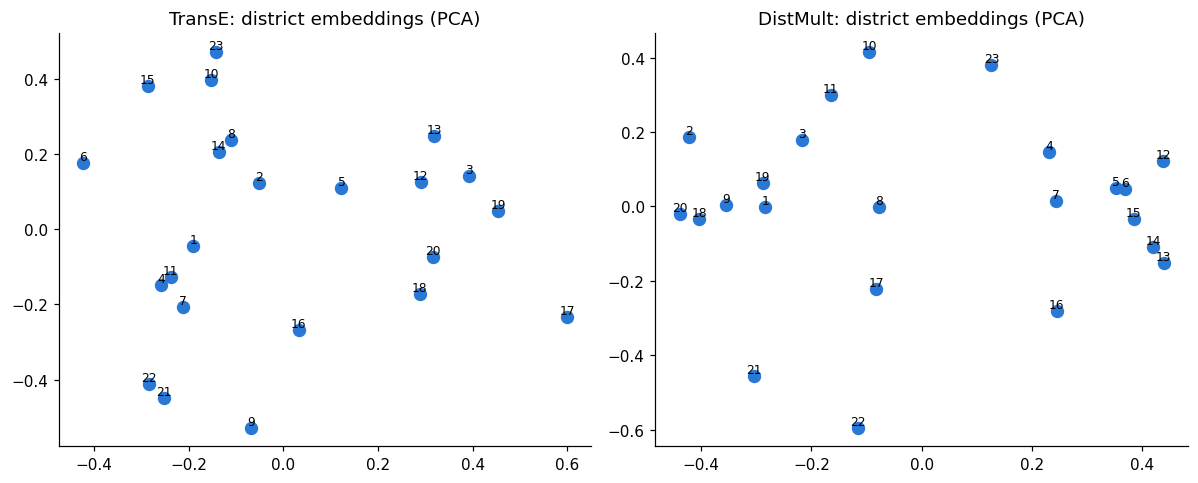

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (model, X) in zip(axes, matrices.items()):
    P2 = PCA(2, random_state=RANDOM_SEED).fit_transform(X)
    ax.scatter(P2[:, 0], P2[:, 1], s=60, color="#2a78d6")
    for i in range(23):
        ax.annotate(str(i + 1), P2[i], fontsize=8, ha="center", va="bottom")
    ax.set_title(f"{model}: district embeddings (PCA)")
plt.tight_layout(); plt.show()

## 2. Transit zones

The pipeline clusters the DistMult vectors with k-means and picks k by silhouette score.
Zone names are generated afterwards from the zones' average features.

In [5]:
from kg.config import CLUSTERS_OUTPUT
clusters = json.loads(CLUSTERS_OUTPUT.read_text())
print("silhouette by k:", clusters["silhouette"])
pd.DataFrame(clusters["clusters"]).set_index("label")

silhouette by k: {'3': 0.291, '4': 0.2859, '5': 0.2667}


,members,mean_accessibility,mean_transit,median_rent_per_sqm,cluster_id,description
label,,,,,,
Zone A,"[1, 2, 3, 8, 9, 10, 11, 17, 18, 19, 20]",0.562,0.441,9.46,0,"Medium network, many direct lines to the centre"
Zone B,"[4, 5, 6, 7, 12, 13, 14, 15, 16, 23]",0.364,0.505,9.54,1,"Dense network, some direct lines to the centre"
Zone C,"[21, 22]",0.182,0.120,9.44,2,"Sparse network, few direct lines to the centre"


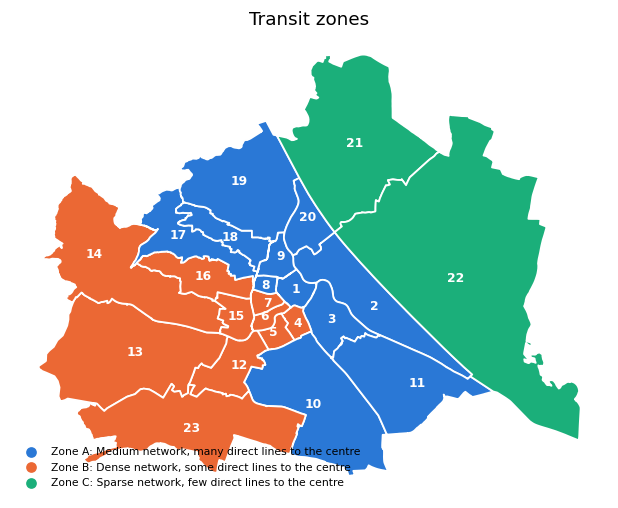

In [6]:
ZONE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(7, 6))
zone = districts["district"].map(lambda d: clusters["districts"][str(d)])
districts.plot(ax=ax, color=[ZONE_COLORS[z] for z in zone], edgecolor="white", linewidth=1.2)
for _, row in districts.iterrows():
    c = row.geometry.representative_point()
    ax.annotate(str(row.district), (c.x, c.y), ha="center", va="center", fontsize=8, color="white", weight="bold")
for c in clusters["clusters"]:
    ax.scatter([], [], color=ZONE_COLORS[c["cluster_id"]], label=f"{c['label']}: {c['description']}")
ax.legend(loc="lower left", fontsize=7, frameon=False); ax.axis("off"); ax.set_title("Transit zones"); plt.show()

The clusters are learned only from *which lines serve which districts*, yet they come out
geographically coherent: the two districts across the Danube (21, 22) form their own zone, and
the rest splits along the network's main axes. This is the kind of structure the embeddings
add on top of the hand-written rules.